# MercadoLibre | Cohort Retention Analysis

## 1. Business Objective

This analysis examines user activity after registration to understand retention patterns across cohorts and user segments.

### Business Questions

1. What percentage of users remain active on D7, D14, D21, and D28?
2. How does retention vary across monthly signup cohorts?
3. Are there differences in retention across countries and devices?
4. Which retention patterns could help identify opportunities to improve user engagement?

### Dataset

- **Source:** `mercadolibre_retention`
- **Unique users:** 12,000
- **Original records:** 696,000
- **Distinct records:** 348,000
- **Observation window:** D0–D28
- **Signup period:** January 1 – August 25, 2025

### Methodology

Users will be grouped into monthly cohorts based on their registration date.

Retention will be measured as the percentage of users who are active on a specific day after signup.

The analysis will:

- Remove exact duplicate records from analytical queries.
- Use `active = 1` to identify active users.
- Calculate D7, D14, D21, and D28 retention.
- Compare retention across cohorts and user segments.
- Validate the observation coverage before interpreting results.

The original SQLite database will remain unchanged.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Database location
db_path = Path("../data/raw/tripleten.db").resolve()

# Connect to SQLite in read-only mode
connection = sqlite3.connect(
    db_path.as_uri() + "?mode=ro",
    uri=True
)

# Verify retention dataset
query = """
WITH retention_clean AS (
    SELECT DISTINCT *
    FROM mercadolibre_retention
)

SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT user_id) AS unique_users,
    MIN(signup_date) AS first_signup,
    MAX(signup_date) AS last_signup
FROM retention_clean;
"""

retention_scope = pd.read_sql_query(query, connection)

display(retention_scope)

,total_records,unique_users,first_signup,last_signup
0,348000,12000,2025-01-01,2025-08-25


## 2. Retention Data Validation

### 2.1 User Observation Coverage

This step checks whether users have complete daily observations from D0 to D28.

It also verifies that the activity indicator contains valid binary values.

These checks help ensure that retention rates are calculated using a consistent observation window.

In [2]:
# Validate user observation coverage and activity values

query = """
WITH user_coverage AS (
    SELECT
        user_id,
        COUNT(DISTINCT day_after_signup) AS observed_days,
        MIN(day_after_signup) AS first_day,
        MAX(day_after_signup) AS last_day
    FROM mercadolibre_retention
    GROUP BY user_id
)

SELECT
    COUNT(*) AS total_users,

    SUM(
        CASE
            WHEN observed_days = 29
             AND first_day = 0
             AND last_day = 28
            THEN 1 ELSE 0
        END
    ) AS users_with_complete_coverage,

    SUM(
        CASE
            WHEN observed_days < 29
            THEN 1 ELSE 0
        END
    ) AS users_with_incomplete_coverage,

    (SELECT COUNT(*)
     FROM mercadolibre_retention
     WHERE active NOT IN (0, 1)
        OR active IS NULL
    ) AS invalid_activity_records

FROM user_coverage;
"""

retention_coverage = pd.read_sql_query(query, connection)

display(retention_coverage)

,total_users,users_with_complete_coverage,users_with_incomplete_coverage,invalid_activity_records
0,12000,12000,0,0


## 3. Overall User Retention

### 3.1 Retention Rates at D7, D14, D21, and D28

This analysis measures the percentage of users who were active on specific days after registration.

Retention is calculated using the original signup population of 12,000 users.

A user is considered retained on a given day when `active = 1`.

In [3]:
# Calculate overall retention rates

query = """
WITH retention_clean AS (
    SELECT DISTINCT
        user_id,
        day_after_signup,
        active
    FROM mercadolibre_retention
)

SELECT
    day_after_signup AS retention_day,

    COUNT(DISTINCT user_id) AS total_users,

    COUNT(DISTINCT CASE
        WHEN active = 1 THEN user_id
    END) AS retained_users,

    ROUND(
        100.0 * COUNT(DISTINCT CASE
            WHEN active = 1 THEN user_id
        END) / COUNT(DISTINCT user_id),
        2
    ) AS retention_rate_pct

FROM retention_clean

WHERE day_after_signup IN (7, 14, 21, 28)

GROUP BY day_after_signup

ORDER BY day_after_signup;
"""

overall_retention = pd.read_sql_query(query, connection)

display(overall_retention)


,retention_day,total_users,retained_users,retention_rate_pct
0,7,12000,2908,24.23
1,14,12000,1389,11.57
2,21,12000,606,5.05
3,28,12000,312,2.60


### 3.2 Daily Retention Curve (D0–D28)

The previous analysis focused on D7, D14, D21, and D28. However, these checkpoints do not reveal when the largest changes in user activity occur.

This analysis calculates daily retention for all 29 days after signup and compares consecutive days to identify the largest observed declines.

Retention is defined as the percentage of registered users who were active on each specific day. It does not measure continuous activity or permanent churn.

Largest day-over-day retention decline:
D0 → D1: -46.53 percentage points


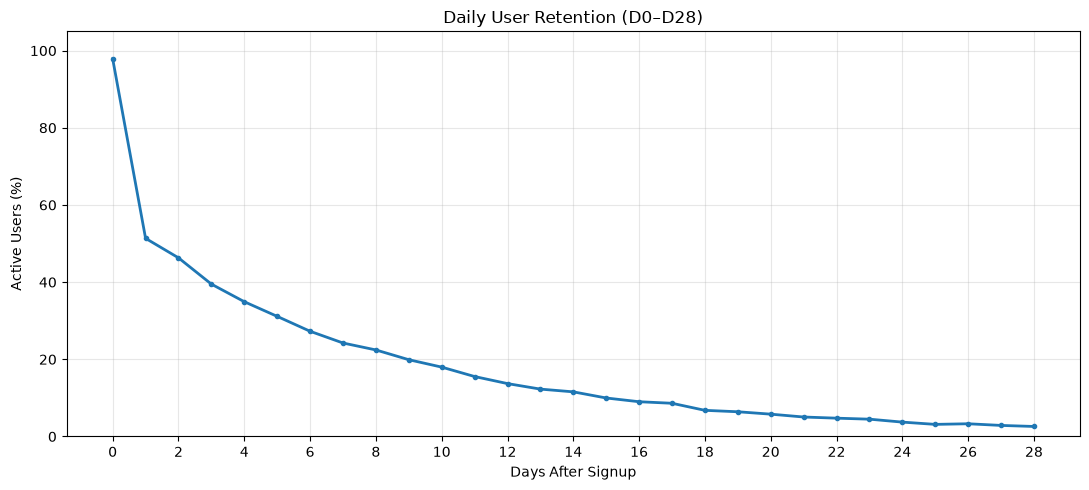

In [4]:
# Calculate daily retention from D0 to D28

query = """
WITH retention_clean AS (
    SELECT DISTINCT
        user_id,
        day_after_signup,
        active
    FROM mercadolibre_retention
)

SELECT
    day_after_signup AS retention_day,
    COUNT(DISTINCT user_id) AS total_users,
    COUNT(DISTINCT CASE
        WHEN active = 1 THEN user_id
    END) AS active_users,
    ROUND(
        100.0 * COUNT(DISTINCT CASE
            WHEN active = 1 THEN user_id
        END) / COUNT(DISTINCT user_id),
        2
    ) AS retention_pct

FROM retention_clean
GROUP BY day_after_signup
ORDER BY day_after_signup;
"""

daily_retention = pd.read_sql_query(query, connection)

# Calculate changes between consecutive days
daily_retention["change_pp"] = (
    daily_retention["retention_pct"].diff().round(2)
)

# Identify the largest day-over-day decline
largest_drop = daily_retention.loc[
    daily_retention["change_pp"].idxmin()
]

print("Largest day-over-day retention decline:")
print(
    f"D{int(largest_drop['retention_day']) - 1} → "
    f"D{int(largest_drop['retention_day'])}: "
    f"{largest_drop['change_pp']:.2f} percentage points"
)

# Visualize daily retention
plt.figure(figsize=(11, 5))

plt.plot(
    daily_retention["retention_day"],
    daily_retention["retention_pct"],
    marker="o",
    markersize=3,
    linewidth=2
)

plt.title("Daily User Retention (D0–D28)")
plt.xlabel("Days After Signup")
plt.ylabel("Active Users (%)")
plt.xticks(range(0, 29, 2))
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Key Findings — Daily Retention

- **The largest day-over-day decline occurs immediately after signup:** daily activity decreases from **97.88% at D0 to 51.35% at D1**, a drop of **46.53 percentage points**.
- **Early activity continues to decline:** retention reaches **39.49% at D3** and **24.23% at D7**.
- **Longer-term activity remains low:** only **2.60%** of registered users are active on D28.

**Business implication:** The first days after signup represent an important opportunity to investigate early engagement. Priorities include examining the onboarding experience, initial product discovery, and opportunities for re-engagement. These are hypotheses to test, not established causes of inactivity.

**Methodological note:** Retention measures activity on each specific day. Users who are inactive on D1 may return later, so these results should not be interpreted as permanent churn.

## 4. Monthly Cohort Retention Analysis

### 4.1 Retention Rates by Signup Cohort

This analysis groups users by their signup month and calculates retention rates at D7, D14, D21, and D28.

The goal is to compare user retention across monthly cohorts and identify differences in engagement patterns.

In [5]:
# Calculate monthly cohort retention rates

query = """
WITH retention_clean AS (
    SELECT DISTINCT
        user_id,
        signup_date,
        day_after_signup,
        active
    FROM mercadolibre_retention
),

monthly_cohorts AS (
    SELECT
        SUBSTR(signup_date, 1, 7) AS cohort_month,
        user_id,

        MAX(CASE WHEN day_after_signup = 7
                 THEN active ELSE 0 END) AS retained_d7,

        MAX(CASE WHEN day_after_signup = 14
                 THEN active ELSE 0 END) AS retained_d14,

        MAX(CASE WHEN day_after_signup = 21
                 THEN active ELSE 0 END) AS retained_d21,

        MAX(CASE WHEN day_after_signup = 28
                 THEN active ELSE 0 END) AS retained_d28

    FROM retention_clean

    GROUP BY cohort_month, user_id
)

SELECT
    cohort_month,
    COUNT(*) AS cohort_size,

    ROUND(100.0 * SUM(retained_d7) / COUNT(*), 2) AS d7_pct,
    ROUND(100.0 * SUM(retained_d14) / COUNT(*), 2) AS d14_pct,
    ROUND(100.0 * SUM(retained_d21) / COUNT(*), 2) AS d21_pct,
    ROUND(100.0 * SUM(retained_d28) / COUNT(*), 2) AS d28_pct

FROM monthly_cohorts

GROUP BY cohort_month
ORDER BY cohort_month;
"""

monthly_retention = pd.read_sql_query(query, connection)

display(monthly_retention)

,cohort_month,cohort_size,d7_pct,d14_pct,d21_pct,d28_pct
0,2025-01,1614,23.48,12.08,4.09,3.04
1,2025-02,1346,23.48,11.81,5.35,2.67
2,2025-03,1610,24.22,13.04,6.09,3.04
3,2025-04,1538,26.07,11.57,4.42,2.02
4,2025-05,1625,24.62,10.22,5.23,3.02
5,2025-06,1505,25.85,11.63,4.98,2.06
6,2025-07,1503,23.29,11.04,5.39,2.73
7,2025-08,1259,22.48,11.12,4.85,2.07


### 4.2 Cohort Retention Heatmap

This heatmap compares D7, D14, D21, and D28 retention rates across monthly signup cohorts.

It helps identify retention patterns and differences between cohorts.

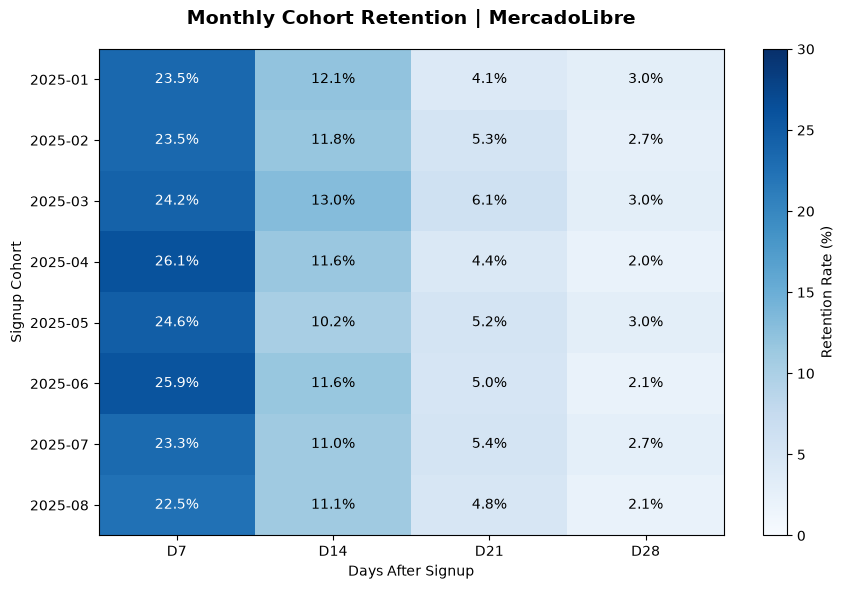

In [6]:
# Visualize monthly cohort retention

import matplotlib.pyplot as plt
import numpy as np

retention_matrix = monthly_retention.set_index("cohort_month")[
    ["d7_pct", "d14_pct", "d21_pct", "d28_pct"]
]

fig, ax = plt.subplots(figsize=(9, 6))

heatmap = ax.imshow(
    retention_matrix,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=30
)

# Axis labels
ax.set_xticks(range(4))
ax.set_xticklabels(["D7", "D14", "D21", "D28"])

ax.set_yticks(range(len(retention_matrix)))
ax.set_yticklabels(retention_matrix.index)

# Display retention percentages
for i in range(len(retention_matrix)):
    for j in range(4):
        value = retention_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value > 15 else "black",
            fontsize=10
        )

ax.set_title(
    "Monthly Cohort Retention | MercadoLibre",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Days After Signup")
ax.set_ylabel("Signup Cohort")

# Color scale
colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Retention Rate (%)")

plt.tight_layout()
plt.show()

## 5. Retention by User Segment

### 5.1 Retention Rates by Country

This analysis compares user retention rates across countries at D7, D14, D21, and D28.

The goal is to identify geographic differences in user engagement and determine whether the overall retention decline is consistent across markets.

In [7]:
# Calculate retention rates by country

query = """
WITH retention_clean AS (
    SELECT DISTINCT
        user_id,
        country,
        day_after_signup,
        active
    FROM mercadolibre_retention
),

user_retention AS (
    SELECT
        user_id,
        country,

        MAX(CASE WHEN day_after_signup = 7
                 THEN active ELSE 0 END) AS retained_d7,

        MAX(CASE WHEN day_after_signup = 14
                 THEN active ELSE 0 END) AS retained_d14,

        MAX(CASE WHEN day_after_signup = 21
                 THEN active ELSE 0 END) AS retained_d21,

        MAX(CASE WHEN day_after_signup = 28
                 THEN active ELSE 0 END) AS retained_d28

    FROM retention_clean
    GROUP BY user_id, country
)

SELECT
    country,
    COUNT(*) AS total_users,

    ROUND(100.0 * SUM(retained_d7) / COUNT(*), 2) AS d7_pct,
    ROUND(100.0 * SUM(retained_d14) / COUNT(*), 2) AS d14_pct,
    ROUND(100.0 * SUM(retained_d21) / COUNT(*), 2) AS d21_pct,
    ROUND(100.0 * SUM(retained_d28) / COUNT(*), 2) AS d28_pct

FROM user_retention

GROUP BY country
ORDER BY total_users DESC;
"""

country_retention = pd.read_sql_query(query, connection)

display(country_retention)

,country,total_users,d7_pct,d14_pct,d21_pct,d28_pct
0,Brazil,3030,26.50,11.49,5.15,2.71
1,Mexico,2411,24.55,13.11,6.06,3.32
2,Colombia,1638,23.87,11.97,4.95,1.83
3,Argentina,1319,24.34,10.77,5.23,2.05
4,Chile,934,21.20,12.42,4.50,2.03
5,Peru,877,21.44,10.03,4.56,3.19
6,Ecuador,598,22.24,10.20,4.01,2.68
7,Bolivia,479,24.43,9.39,4.18,2.51
8,Paraguay,470,22.13,10.43,4.47,2.34
9,Uruguay,244,25.00,11.48,2.87,2.87


### 5.2 Device Segmentation Validation

Before comparing retention by device, this step checks whether each user has a consistent device category.

This validation helps prevent users from being counted in multiple device segments.

In [8]:
# Validate device categories per user

query = """
WITH user_devices AS (
    SELECT
        user_id,
        COUNT(DISTINCT device_category) AS device_count
    FROM mercadolibre_retention
    GROUP BY user_id
)

SELECT
    COUNT(*) AS total_users,

    SUM(
        CASE WHEN device_count = 1
        THEN 1 ELSE 0 END
    ) AS users_with_one_device,

    SUM(
        CASE WHEN device_count > 1
        THEN 1 ELSE 0 END
    ) AS users_with_multiple_devices,

    SUM(
        CASE WHEN device_count = 0
        THEN 1 ELSE 0 END
    ) AS users_without_device

FROM user_devices;
"""

device_validation = pd.read_sql_query(query, connection)

display(device_validation)

,total_users,users_with_one_device,users_with_multiple_devices,users_without_device
0,12000,12000,0,0


### 5.3 Retention Rates by Device

This analysis compares user retention rates across device categories at D7, D14, D21, and D28.

The goal is to identify differences in user engagement between devices.

In [9]:
# Calculate retention rates by device

query = """
WITH retention_clean AS (
    SELECT DISTINCT
        user_id,
        device_category,
        day_after_signup,
        active
    FROM mercadolibre_retention
),

user_retention AS (
    SELECT
        user_id,
        device_category,

        MAX(CASE WHEN day_after_signup = 7
                 THEN active ELSE 0 END) AS retained_d7,

        MAX(CASE WHEN day_after_signup = 14
                 THEN active ELSE 0 END) AS retained_d14,

        MAX(CASE WHEN day_after_signup = 21
                 THEN active ELSE 0 END) AS retained_d21,

        MAX(CASE WHEN day_after_signup = 28
                 THEN active ELSE 0 END) AS retained_d28

    FROM retention_clean
    GROUP BY user_id, device_category
)

SELECT
    device_category,
    COUNT(*) AS total_users,

    ROUND(100.0 * SUM(retained_d7) / COUNT(*), 2) AS d7_pct,
    ROUND(100.0 * SUM(retained_d14) / COUNT(*), 2) AS d14_pct,
    ROUND(100.0 * SUM(retained_d21) / COUNT(*), 2) AS d21_pct,
    ROUND(100.0 * SUM(retained_d28) / COUNT(*), 2) AS d28_pct

FROM user_retention

GROUP BY device_category
ORDER BY total_users DESC;
"""

device_retention = pd.read_sql_query(query, connection)

display(device_retention)

,device_category,total_users,d7_pct,d14_pct,d21_pct,d28_pct
0,mobile,8963,25.25,12.02,5.24,2.76
1,desktop,2421,21.23,10.08,4.46,2.11
2,tablet,616,21.27,11.04,4.55,2.27


### 5.4 Device Retention Comparison

This chart compares D7 and D28 retention rates across device categories.

It highlights differences in early and later user engagement.

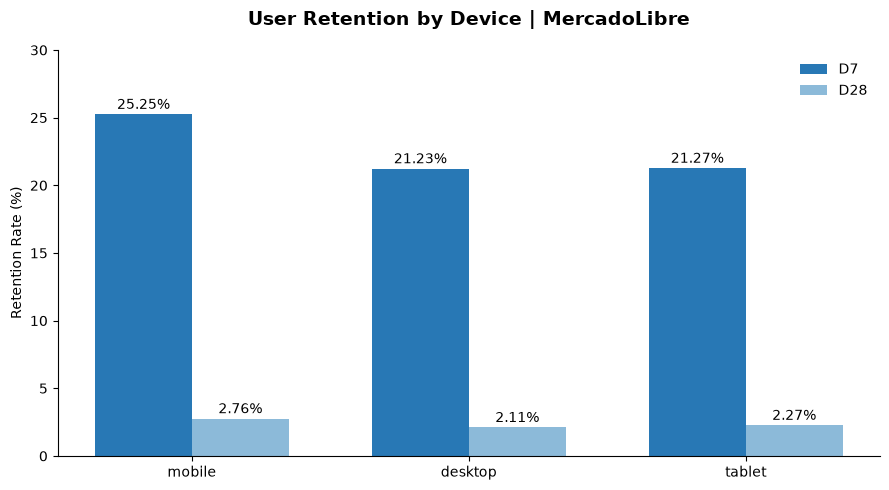

In [10]:
# Compare D7 and D28 retention by device

import matplotlib.pyplot as plt
import numpy as np

devices = device_retention["device_category"]
d7 = device_retention["d7_pct"]
d28 = device_retention["d28_pct"]

x = np.arange(len(devices))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_d7 = ax.bar(
    x - width / 2,
    d7,
    width,
    label="D7",
    color="#2878B5"
)

bars_d28 = ax.bar(
    x + width / 2,
    d28,
    width,
    label="D28",
    color="#8CBAD9"
)

# Display percentages above bars
for bars in [bars_d7, bars_d28]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.4,
            f"{bar.get_height():.2f}%",
            ha="center",
            fontsize=10
        )

ax.set_title(
    "User Retention by Device | MercadoLibre",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xticks(x)
ax.set_xticklabels(devices)

ax.set_ylabel("Retention Rate (%)")
ax.set_ylim(0, 30)

ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## 6. Key Findings and Business Recommendations

### 6.1 Key Findings

**1. User activity declines substantially during the first 28 days.**

Overall retention decreases from **24.23% at D7** to **2.60% at D28**.

| Retention Day | Active Users | Retention Rate |
|---|---:|---:|
| D7 | 2,908 | 24.23% |
| D14 | 1,389 | 11.57% |
| D21 | 606 | 5.05% |
| D28 | 312 | 2.60% |

The largest decrease between the measured intervals occurs from D7 to D14, with a difference of **12.66 percentage points**.

**2. Monthly cohorts show a similar retention pattern.**

Across all eight monthly cohorts, D7 retention ranges from approximately 22% to 26%, while D28 retention remains close to 2%–3%.

There is no consistent improvement in retention across more recent cohorts.

**3. Retention declines across all countries.**

Mexico has the highest observed D28 retention rate (3.32%), while Colombia has the lowest (1.83%).

However, all countries show low activity levels by D28.

**4. Mobile users show higher retention than other device segments.**

Mobile represents approximately 74.7% of the user population.

| Device | Users | D7 | D28 |
|---|---:|---:|---:|
| Mobile | 8,963 | 25.25% | 2.76% |
| Desktop | 2,421 | 21.23% | 2.11% |
| Tablet | 616 | 21.27% | 2.27% |

Mobile has the highest observed retention at both D7 and D28. However, retention is low across all device categories after four weeks.

### 6.2 Business Recommendations

**Investigate early user engagement.**

Review the first two weeks after registration to understand why activity decreases substantially between D7 and D14.

**Evaluate onboarding and re-engagement opportunities.**

Consider testing improvements to the onboarding experience, personalized recommendations, and re-engagement communications.

These are potential actions to evaluate, not proven solutions.

**Monitor retention across user segments.**

Track retention by country and device to identify meaningful changes over time.

**Use experiments to evaluate improvements.**

Test proposed changes and measure whether they improve D7, D14, and D28 retention compared with a control group.

### 6.3 Analysis Limitations

- The dataset contains 12,000 users with complete daily observations from D0 to D28.
- Exact duplicate records were excluded from retention calculations.
- Retention represents activity on a specific day after signup, not continuous activity throughout the period.
- The analysis measures user activity, not purchase retention.
- Geographic and device comparisons are descriptive and do not establish causal relationships.
- The data does not explain why individual users become inactive.
- The retention and purchase funnel datasets represent different analytical populations and should not be combined without validating their relationship.

### 6.4 Conclusion

The main finding is a substantial decrease in user activity during the first 28 days after registration.

This pattern appears across monthly cohorts, countries, and device categories.

The results suggest that improving early engagement and evaluating user re-engagement strategies could be useful priorities for further investigation.

Additional behavioral data and controlled experiments would be needed to identify the causes of inactivity and measure the effectiveness of proposed improvements.